# ClearBank — Análise Financeira com Python

**Desafio final · Pós-Graduação Rocketseat · Análise de Dados e Inteligência de Negócios com IA**

## 1. Contexto e objetivo

A ClearBank é uma fintech fictícia que recebe um extrato de transações em CSV com problemas comuns de qualidade: IDs faltando, clientes em branco, datas mal formatadas, tipos desconhecidos e valores inválidos.

Este notebook:

1. lê `transacoes.csv` usando **somente o módulo nativo `csv`**;
2. valida e limpa cada linha, contando e registrando os motivos de rejeição;
3. converte as datas com `datetime.strptime()` e agrupa por mês (`AAAA-MM`);
4. calcula métricas financeiras mensais;
5. sinaliza transações acima do limite de suspeição (`LIMITE_SUSPEITO`);
6. exibe um relatório formatado em padrão brasileiro (`R$ 3.500,00`);
7. exporta tudo para `relatorio.json`;
8. demonstra o funcionamento com testes (`assert`) e saídas visíveis.

> A solução principal não usa pandas nem bibliotecas externas. O `matplotlib` aparece apenas no gráfico opcional, e o pandas apenas no script opcional `analise_pandas.py`.

## 2. Requisitos e instruções de execução

**Requisitos:** Python 3.10 ou superior. Nenhuma biblioteca externa é necessária para a solução principal.

**Jupyter local**

1. Deixe `desafio-final.ipynb` e `transacoes.csv` na **mesma pasta** (`clearbank-analise/`).
2. Abra o notebook a partir dessa pasta (o diretório de trabalho deve ser `clearbank-analise/`).
3. Menu *Kernel → Restart & Run All*.

**Google Colab**

1. Abra o notebook no Colab.
2. Execute as células em ordem. Se `transacoes.csv` não estiver em `/content`, a célula do final da seção 3 abre um seletor para enviar o arquivo.
3. Os arquivos gerados ficam em `/content` (painel *Arquivos*, à esquerda).

**Arquivos gerados** na mesma pasta do notebook: `relatorio.json` e, se o `matplotlib` estiver disponível, `grafico.png`.

## 3. Importações e constantes

Todos os módulos são da biblioteca padrão. Valores monetários usam `Decimal` para evitar erros de representação binária do `float` (por exemplo, `0.1 + 0.2 != 0.3`). A precisão do `Decimal` é ampliada para 80 dígitos, o que mantém as contas exatas dentro dos limites técnicos explicados na seção 5.

`LIMITE_SUSPEITO` fica definido como `10000.00`, conforme o enunciado. Para comparar com valores `Decimal`, ele é convertido uma única vez em `LIMITE_SUSPEITO_DECIMAL` via `Decimal(str(...))`, o que preserva o valor exato `10000.0`.

In [1]:
import csv
import io
import json
import re
import tempfile
import uuid
from contextlib import redirect_stdout
from datetime import date, datetime
from decimal import Decimal, InvalidOperation, ROUND_HALF_UP, getcontext
from pathlib import Path

LIMITE_SUSPEITO = 10000.00

COLUNAS_OBRIGATORIAS = ("id", "data", "cliente_id", "tipo", "valor", "descricao", "categoria")
TIPOS_VALIDOS = ("credito", "debito")
FORMATO_DATA = "%Y-%m-%d"
# AAAA-MM-DD com zeros à esquerda; re.ASCII faz \d aceitar só os dígitos 0-9
PADRAO_DATA = re.compile(r"\d{4}-\d{2}-\d{2}", re.ASCII)

# Limites técnicos (não são regras de negócio) — justificativa na seção 5
PRECISAO_DECIMAL = 80          # dígitos significativos nas contas com Decimal
MAGNITUDE_MAXIMA = 40          # aceita valores menores que 10**40
CASAS_DECIMAIS_MAXIMAS = 10    # aceita até 10 casas decimais significativas
getcontext().prec = PRECISAO_DECIMAL

LIMITE_SUSPEITO_DECIMAL = Decimal(str(LIMITE_SUSPEITO))
MARCADOR_DECIMAL = f"__decimal_{uuid.uuid4().hex}__"  # usado só na gravação do JSON (seção 11)

PASTA_PROJETO = Path.cwd()
CAMINHO_CSV = PASTA_PROJETO / "transacoes.csv"
CAMINHO_JSON = PASTA_PROJETO / "relatorio.json"
CAMINHO_GRAFICO = PASTA_PROJETO / "grafico.png"

print(f"Pasta do projeto: {PASTA_PROJETO}")
print(f"CSV de entrada encontrado? {CAMINHO_CSV.exists()}")
print(f"Limite de suspeição: {LIMITE_SUSPEITO_DECIMAL}")

Pasta do projeto: /home/claude/clearbank-analise
CSV de entrada encontrado? True
Limite de suspeição: 10000.0


In [2]:
# Apenas no Google Colab: envia o CSV caso ele ainda não esteja na pasta de trabalho.
try:
    from google.colab import files as colab_files
except ImportError:
    colab_files = None  # Jupyter local: nada a fazer

if colab_files is not None and not CAMINHO_CSV.exists():
    print("Selecione o arquivo transacoes.csv para enviar ao Colab.")
    enviados = colab_files.upload()
    print("Arquivos enviados:", list(enviados))
    if not CAMINHO_CSV.exists():
        print("Atenção: renomeie o arquivo enviado para 'transacoes.csv'.")
else:
    print("Envio pelo Colab não necessário.")

Envio pelo Colab não necessário.


## 4. Funções de leitura

`ler_transacoes()` abre o arquivo com `open(..., encoding="utf-8")` dentro de um `with` (o arquivo é fechado mesmo se ocorrer erro) e usa `csv.DictReader`, acessando as colunas pelo nome.

Dois erros de entrada são tratados aqui:

- **`FileNotFoundError`** — capturado e relançado com uma mensagem clara que inclui o caminho procurado;
- **`CabecalhoInvalidoError`** — exceção própria (subclasse de `ValueError`) para arquivo vazio ou cabeçalho sem as colunas obrigatórias.

Cada registro recebe a chave interna `_linha` com o número da linha no arquivo, usada na auditoria das rejeições.

In [3]:
class CabecalhoInvalidoError(ValueError):
    """Erro de entrada: o CSV está vazio ou não tem as colunas obrigatórias."""


def validar_cabecalho(colunas):
    """Confere se todas as colunas obrigatórias existem no cabeçalho do CSV."""
    if not colunas:
        raise CabecalhoInvalidoError("o arquivo está vazio ou não possui cabeçalho")
    ausentes = [coluna for coluna in COLUNAS_OBRIGATORIAS if coluna not in colunas]
    if ausentes:
        raise CabecalhoInvalidoError(f"colunas obrigatórias ausentes: {', '.join(ausentes)}")


def ler_transacoes(caminho):
    """Lê o CSV e devolve uma lista de dicionários (um por linha de dados).

    Lança FileNotFoundError se o arquivo não existir e
    CabecalhoInvalidoError se o cabeçalho for inválido.
    """
    caminho = Path(caminho)
    try:
        with open(caminho, mode="r", encoding="utf-8", newline="") as arquivo:
            leitor = csv.DictReader(arquivo)
            colunas = leitor.fieldnames
            if colunas and colunas[0].startswith("﻿"):
                # CSV salvo pelo Excel começa com BOM; sem isto a coluna "id" viraria "﻿id"
                leitor.fieldnames = [colunas[0].lstrip("﻿"), *colunas[1:]]
            validar_cabecalho(leitor.fieldnames)
            registros = []
            for registro in leitor:
                registro["_linha"] = leitor.line_num
                registros.append(registro)
    except FileNotFoundError as erro:
        raise FileNotFoundError(f"arquivo CSV não encontrado: {caminho}") from erro
    return registros

## 5. Funções de validação e limpeza

Cada campo obrigatório tem um validador pequeno, que **converte** o texto ou lança `ValueError` com o motivo da rejeição:

| Campo | Regra | Conversão |
|---|---|---|
| `id` | obrigatório e inteiro | `int()` |
| `cliente_id` | não pode ser vazio nem só espaços | `str.strip()` |
| `data` | exatamente `AAAA-MM-DD` e data existente | `datetime.strptime()` |
| `tipo` | apenas `credito` ou `debito` | — |
| `valor` | numérico, finito e maior que zero (+ limites técnicos abaixo) | `Decimal()` |

`validar_transacao()` executa todos os validadores, cada um em um `try/except ValueError` específico, e devolve `(transacao, [])` ou `(None, motivos)`. Assim uma linha pode ter vários motivos registrados e **nunca interrompe** o processamento das demais.

Decisões documentadas:

- `descricao` e `categoria` não são obrigatórias. Quando vazias ou ausentes, são representadas como string vazia `""`.
- Espaços nas bordas dos campos são removidos antes da validação. O `tipo` é comparado com distinção entre maiúsculas e minúsculas (`Credito` é rejeitado).
- `strptime` aceitaria `2026-3-5`; por isso a expressão regular `PADRAO_DATA` exige antes os dígitos com zero à esquerda.
- `Decimal()` lança `InvalidOperation` para texto não numérico; o validador converte isso em `ValueError`, mantendo um único tipo de erro de entrada.
- **Notação do valor:** qualquer texto que o `Decimal` converte é aceito, inclusive `1e30`, `0.001`, `10000.004` e `1_000`. O mesmo vale para o `id` com `int()`. Nenhuma linha é rejeitada só pela forma de escrever o número.
- **Limites técnicos do valor** (não são regras de negócio): o valor precisa ser menor que `10**40` e ter no máximo 10 casas decimais significativas. Assim, cada valor tem no máximo 50 dígitos, e com precisão de 80 dígitos qualquer soma do arquivo continua **exata**. Sem esses limites, um valor como `1e1000000` estoura o `Decimal` (`Overflow`) e derruba a análise inteira, e valores com escalas muito diferentes passariam a ser arredondados em silêncio. Impacto: só valores absurdos para um extrato bancário são recusados, sempre com motivo registrado.
- A data continua exigindo os dígitos ASCII `0-9`, porque o formato `AAAA-MM-DD` é exigido literalmente.
- Um BOM no início do arquivo (comum em CSV salvo pelo Excel) é removido do nome da primeira coluna.
- **Duplicidades:** o enunciado não define regra de deduplicação, então linhas com o mesmo `id` **não são removidas**. Elas apenas aparecem na detecção informativa `detectar_ids_duplicados()`, separada das regras obrigatórias.

In [4]:
def texto_do_campo(registro, campo):
    """Devolve o texto do campo sem espaços nas bordas ('' se ausente)."""
    valor = registro.get(campo)
    return "" if valor is None else valor.strip()


def casas_decimais(valor):
    """Casas decimais significativas de um Decimal: 10000.00 → 0, 10000.004 → 3, 1E+30 → 0."""
    _, digitos, expoente = valor.as_tuple()
    texto = "".join(map(str, digitos))
    zeros_a_direita = len(texto) - len(texto.rstrip("0"))
    return max(0, -(expoente + zeros_a_direita)) if texto.rstrip("0") else 0


def validar_id(texto):
    if not texto:
        raise ValueError("id ausente")
    try:
        return int(texto)
    except ValueError as erro:
        raise ValueError(f"id não é inteiro: {texto!r}") from erro


def validar_cliente(texto):
    if not texto:
        raise ValueError("cliente_id vazio")
    return texto


def converter_data(texto):
    if not PADRAO_DATA.fullmatch(texto):
        raise ValueError(f"data fora do formato AAAA-MM-DD: {texto!r}")
    try:
        return datetime.strptime(texto, FORMATO_DATA)
    except ValueError as erro:
        raise ValueError(f"data inexistente: {texto!r}") from erro


def validar_tipo(texto):
    if texto not in TIPOS_VALIDOS:
        raise ValueError(f"tipo inválido: {texto!r} (use 'credito' ou 'debito')")
    return texto


def converter_valor(texto):
    if not texto:
        raise ValueError("valor ausente")
    try:
        valor = Decimal(texto)
    except InvalidOperation as erro:
        raise ValueError(f"valor não numérico: {texto!r}") from erro
    if not valor.is_finite():
        raise ValueError(f"valor não finito: {texto!r}")
    if valor <= 0:
        raise ValueError(f"valor deve ser maior que zero: {texto!r}")
    if valor.adjusted() >= MAGNITUDE_MAXIMA:
        raise ValueError(f"valor fora da faixa suportada (deve ser menor que 1e{MAGNITUDE_MAXIMA}): {texto[:30]!r}")
    if casas_decimais(valor) > CASAS_DECIMAIS_MAXIMAS:
        raise ValueError(f"valor com mais de {CASAS_DECIMAIS_MAXIMAS} casas decimais: {texto[:30]!r}")
    return valor


VALIDADORES = (
    ("id", validar_id),
    ("cliente_id", validar_cliente),
    ("data", converter_data),
    ("tipo", validar_tipo),
    ("valor", converter_valor),
)


def validar_transacao(registro):
    """Valida um registro bruto do CSV.

    Retorna (transacao, []) quando válido ou (None, motivos) quando inválido.
    """
    motivos = []
    if None in registro:  # DictReader guarda colunas excedentes na chave None
        motivos.append("linha com mais colunas que o cabeçalho")

    convertidos = {}
    for campo, validador in VALIDADORES:
        try:
            convertidos[campo] = validador(texto_do_campo(registro, campo))
        except ValueError as erro:
            motivos.append(str(erro))

    if motivos:
        return None, motivos

    transacao = {
        "id": convertidos["id"],
        "data": convertidos["data"],
        "cliente_id": convertidos["cliente_id"],
        "tipo": convertidos["tipo"],
        "valor": convertidos["valor"],
        "descricao": texto_do_campo(registro, "descricao"),
        "categoria": texto_do_campo(registro, "categoria"),
        "linha": registro.get("_linha"),
    }
    return transacao, []


def limpar_transacoes(registros):
    """Separa registros válidos e rejeitados, guardando os motivos de cada rejeição."""
    validas, rejeitadas = [], []
    for registro in registros:
        transacao, motivos = validar_transacao(registro)
        if transacao is None:
            rejeitadas.append({
                "linha": registro.get("_linha"),
                "id_informado": texto_do_campo(registro, "id"),
                "motivos": motivos,
            })
        else:
            validas.append(transacao)
    return validas, rejeitadas


def detectar_ids_duplicados(transacoes):
    """Detecção informativa: IDs que aparecem mais de uma vez entre as válidas."""
    linhas_por_id = {}
    for transacao in transacoes:
        linhas_por_id.setdefault(transacao["id"], []).append(transacao["linha"])
    return [
        {"id": id_transacao, "linhas": linhas}
        for id_transacao, linhas in sorted(linhas_por_id.items())
        if len(linhas) > 1
    ]

## 6. Testes das validações e dos tratamentos de exceção

Os testes usam `assert`. Uma rejeição **esperada** imprime `OK`; uma falha real interrompe a célula com `AssertionError` e a mensagem do caso que falhou.

Os testes de leitura criam arquivos em uma pasta temporária (`tempfile.TemporaryDirectory`), apagada ao final, sem tocar nos arquivos do projeto.

In [5]:
def verificar(descricao, condicao):
    assert condicao, f"FALHOU: {descricao}"
    print(f"OK  {descricao}")


def registro_teste(**alteracoes):
    base = {"id": "1", "data": "2026-01-10", "cliente_id": "C001", "tipo": "credito",
            "valor": "100.00", "descricao": "Teste", "categoria": "teste", "_linha": 2}
    base.update(alteracoes)
    return base


def rejeitado_por(registro, trecho):
    transacao, motivos = validar_transacao(registro)
    return transacao is None and any(trecho in motivo for motivo in motivos)


print("--- Registro válido ---")
transacao, motivos = validar_transacao(registro_teste())
verificar("registro válido é aceito", transacao is not None and motivos == [])
verificar("id convertido para int", transacao["id"] == 1)
verificar("data convertida para datetime", transacao["data"] == datetime(2026, 1, 10))
verificar("valor convertido para Decimal", transacao["valor"] == Decimal("100.00"))
transacao, _ = validar_transacao(registro_teste(descricao="", categoria="   "))
verificar("descrição/categoria vazias são aceitas como ''",
          transacao["descricao"] == "" and transacao["categoria"] == "")

print("\n--- id ---")
verificar("id vazio é rejeitado", rejeitado_por(registro_teste(id=""), "id ausente"))
verificar("id 'ABC' é rejeitado", rejeitado_por(registro_teste(id="ABC"), "id não é inteiro"))
verificar("id '1.5' é rejeitado", rejeitado_por(registro_teste(id="1.5"), "id não é inteiro"))

print("\n--- cliente_id ---")
verificar("cliente vazio é rejeitado", rejeitado_por(registro_teste(cliente_id=""), "cliente_id vazio"))
verificar("cliente só com espaços é rejeitado", rejeitado_por(registro_teste(cliente_id="   "), "cliente_id vazio"))

print("\n--- data ---")
verificar("data 15/02/2026 é rejeitada", rejeitado_por(registro_teste(data="15/02/2026"), "fora do formato"))
verificar("data 2026-3-5 é rejeitada", rejeitado_por(registro_teste(data="2026-3-5"), "fora do formato"))
verificar("data 2026-02-30 é rejeitada", rejeitado_por(registro_teste(data="2026-02-30"), "data inexistente"))
verificar("data vazia é rejeitada", rejeitado_por(registro_teste(data=""), "fora do formato"))
verificar("29/02 em ano bissexto é aceito", validar_transacao(registro_teste(data="2028-02-29"))[0] is not None)

print("\n--- tipo ---")
verificar("tipo 'transferencia' é rejeitado", rejeitado_por(registro_teste(tipo="transferencia"), "tipo inválido"))
verificar("tipo 'Credito' é rejeitado", rejeitado_por(registro_teste(tipo="Credito"), "tipo inválido"))
verificar("tipo 'debito' é aceito", validar_transacao(registro_teste(tipo="debito"))[0] is not None)

print("\n--- valor ---")
verificar("valor 'mil reais' é rejeitado", rejeitado_por(registro_teste(valor="mil reais"), "não numérico"))
verificar("valor '1.500,00' é rejeitado", rejeitado_por(registro_teste(valor="1.500,00"), "não numérico"))
verificar("valor 0 é rejeitado", rejeitado_por(registro_teste(valor="0"), "maior que zero"))
verificar("valor negativo é rejeitado", rejeitado_por(registro_teste(valor="-150.00"), "maior que zero"))
verificar("valor NaN é rejeitado", rejeitado_por(registro_teste(valor="NaN"), "não finito"))
verificar("valor Infinity é rejeitado", rejeitado_por(registro_teste(valor="Infinity"), "não finito"))
verificar("valor vazio é rejeitado", rejeitado_por(registro_teste(valor=""), "valor ausente"))

print("\n--- valor: notações aceitas (sem arredondar) ---")
def valor_aceito(texto):
    transacao, _ = validar_transacao(registro_teste(valor=texto))
    return None if transacao is None else transacao["valor"]

verificar("'1e30' aceito como 10**30", valor_aceito("1e30") == Decimal(10) ** 30)
verificar("'0.001' aceito sem arredondar", valor_aceito("0.001") == Decimal("0.001"))
verificar("'10000.004' aceito sem arredondar", valor_aceito("10000.004") == Decimal("10000.004"))
verificar("'1_000' aceito como 1000 (sintaxe aceita pelo Decimal)", valor_aceito("1_000") == Decimal(1000))
verificar("dígitos não ASCII '١٢' aceitos como 12", valor_aceito("١٢") == Decimal(12))

print("\n--- valor: limites técnicos ---")
verificar("'1e40' (magnitude) é rejeitado", rejeitado_por(registro_teste(valor="1e40"), "fora da faixa"))
verificar("'1e1000000' é rejeitado sem Overflow", rejeitado_por(registro_teste(valor="1e1000000"), "fora da faixa"))
verificar("maior valor suportado é aceito", valor_aceito("9" * 40 + ".9999999999") is not None)
verificar("11 casas decimais são rejeitadas", rejeitado_por(registro_teste(valor="0.00000000001"), "casas decimais"))
verificar("zeros à direita não contam como casas", valor_aceito("5.100000000000000") == Decimal("5.1"))
verificar("casas_decimais: 10000.00→0, 10000.004→3, 1E+30→0",
          [casas_decimais(Decimal(t)) for t in ("10000.00", "10000.004", "1e30")] == [0, 3, 0])

print("\n--- dígitos não ASCII em id e data ---")
transacao, _ = validar_transacao(registro_teste(id="١٢"))
verificar("id '١٢' aceito como 12 (int() converte com segurança)", transacao is not None and transacao["id"] == 12)
verificar("data com dígitos não ASCII é rejeitada (formato AAAA-MM-DD)", rejeitado_por(registro_teste(data="٢٠٢٦-٠١-٠١"), "fora do formato"))

print("\n--- linha com vários problemas ---")
_, motivos = validar_transacao(registro_teste(id="", cliente_id="", tipo="pix"))
verificar("todos os motivos são registrados", len(motivos) == 3)
_, motivos = validar_transacao({**registro_teste(), None: ["coluna extra"]})
verificar("coluna excedente é rejeitada", "linha com mais colunas que o cabeçalho" in motivos)

--- Registro válido ---
OK  registro válido é aceito
OK  id convertido para int
OK  data convertida para datetime
OK  valor convertido para Decimal
OK  descrição/categoria vazias são aceitas como ''

--- id ---
OK  id vazio é rejeitado
OK  id 'ABC' é rejeitado
OK  id '1.5' é rejeitado

--- cliente_id ---
OK  cliente vazio é rejeitado
OK  cliente só com espaços é rejeitado

--- data ---
OK  data 15/02/2026 é rejeitada
OK  data 2026-3-5 é rejeitada
OK  data 2026-02-30 é rejeitada
OK  data vazia é rejeitada
OK  29/02 em ano bissexto é aceito

--- tipo ---
OK  tipo 'transferencia' é rejeitado
OK  tipo 'Credito' é rejeitado
OK  tipo 'debito' é aceito

--- valor ---
OK  valor 'mil reais' é rejeitado
OK  valor '1.500,00' é rejeitado
OK  valor 0 é rejeitado
OK  valor negativo é rejeitado
OK  valor NaN é rejeitado
OK  valor Infinity é rejeitado
OK  valor vazio é rejeitado

--- valor: notações aceitas (sem arredondar) ---
OK  '1e30' aceito como 10**30
OK  '0.001' aceito sem arredondar
OK  '10000

In [6]:
CABECALHO_CSV = ",".join(COLUNAS_OBRIGATORIAS)


def criar_csv(pasta, nome, conteudo):
    caminho = Path(pasta) / nome
    caminho.write_text(conteudo, encoding="utf-8")
    return caminho


with tempfile.TemporaryDirectory() as pasta_temp:
    print("--- Leitura ---")
    try:
        ler_transacoes(Path(pasta_temp) / "nao_existe.csv")
        raise AssertionError("FALHOU: deveria lançar FileNotFoundError")
    except FileNotFoundError as erro:
        verificar(f"arquivo inexistente → FileNotFoundError ({erro})", True)

    vazio = criar_csv(pasta_temp, "vazio.csv", "")
    try:
        ler_transacoes(vazio)
        raise AssertionError("FALHOU: deveria lançar CabecalhoInvalidoError")
    except CabecalhoInvalidoError as erro:
        verificar(f"arquivo vazio → CabecalhoInvalidoError ({erro})", True)

    errado = criar_csv(pasta_temp, "cabecalho.csv", "id,data,cliente,tipo,valor\n1,2026-01-01,C1,credito,10\n")
    try:
        ler_transacoes(errado)
        raise AssertionError("FALHOU: deveria lançar CabecalhoInvalidoError")
    except CabecalhoInvalidoError as erro:
        verificar(f"cabeçalho incorreto → CabecalhoInvalidoError ({erro})", True)

    com_bom = Path(pasta_temp) / "bom.csv"
    com_bom.write_text("﻿" + CABECALHO_CSV + "\n1,2026-01-01,C1,credito,10,,\n", encoding="utf-8")
    verificar("CSV com BOM (Excel) é lido normalmente", [r["id"] for r in ler_transacoes(com_bom)] == ["1"])

    so_cabecalho = criar_csv(pasta_temp, "so_cabecalho.csv", CABECALHO_CSV + "\n")
    verificar("arquivo só com cabeçalho → lista vazia", ler_transacoes(so_cabecalho) == [])

    misto = criar_csv(pasta_temp, "misto.csv", CABECALHO_CSV + "\n"
                      "1,2026-01-01,C1,credito,10,,\n"
                      "X,data ruim,,pix,abc,,\n"
                      "2,2026-01-02,C2,debito,5,,\n")
    validas, rejeitadas = limpar_transacoes(ler_transacoes(misto))
    verificar("linha inválida no meio não interrompe o processamento",
              [t["id"] for t in validas] == [1, 2] and len(rejeitadas) == 1)
    verificar("rejeição guarda a linha do arquivo", rejeitadas[0]["linha"] == 3)

--- Leitura ---
OK  arquivo inexistente → FileNotFoundError (arquivo CSV não encontrado: /tmp/tmpxobbp9ys/nao_existe.csv)
OK  arquivo vazio → CabecalhoInvalidoError (o arquivo está vazio ou não possui cabeçalho)
OK  cabeçalho incorreto → CabecalhoInvalidoError (colunas obrigatórias ausentes: cliente_id, descricao, categoria)
OK  CSV com BOM (Excel) é lido normalmente
OK  arquivo só com cabeçalho → lista vazia
OK  linha inválida no meio não interrompe o processamento
OK  rejeição guarda a linha do arquivo


### Demonstração dos três tratamentos de exceção obrigatórios

Abaixo, cada situação é provocada de propósito e capturada com um `except` **específico**, sem `except Exception`.

In [7]:
print("1) FileNotFoundError na leitura do CSV")
try:
    ler_transacoes("arquivo_que_nao_existe.csv")
except FileNotFoundError as erro:
    print(f"   capturado: {erro}")

print("\n2) ValueError na conversão de valores")
try:
    converter_valor("mil reais")
except ValueError as erro:
    print(f"   capturado: {erro}")

print("\n3) ValueError na conversão de datas")
try:
    converter_data("2026-02-30")
except ValueError as erro:
    print(f"   capturado: {erro}")
    print(f"   causa original (strptime): {erro.__cause__}")

1) FileNotFoundError na leitura do CSV
   capturado: arquivo CSV não encontrado: arquivo_que_nao_existe.csv

2) ValueError na conversão de valores
   capturado: valor não numérico: 'mil reais'

3) ValueError na conversão de datas
   capturado: data inexistente: '2026-02-30'
   causa original (strptime): day is out of range for month


## 7. Conversão e análise de datas

As datas já chegam aqui como objetos `datetime` (convertidas na validação). Esta seção:

- extrai o mês no formato `AAAA-MM` com `strftime("%Y-%m")`;
- calcula o período analisado: data mais antiga, mais recente e o intervalo em dias (`(fim - inicio).days`).

Sem transações válidas, o período é devolvido com `inicio` e `fim` iguais a `None` e intervalo `0`, sem exceção.

In [8]:
def extrair_mes(data):
    """Devolve o mês da data no formato AAAA-MM."""
    return data.strftime("%Y-%m")


def calcular_periodo(transacoes):
    """Primeira data, última data e quantidade de dias entre elas."""
    if not transacoes:
        return {"inicio": None, "fim": None, "intervalo_dias": 0}
    datas = [transacao["data"] for transacao in transacoes]
    inicio, fim = min(datas), max(datas)
    return {
        "inicio": inicio.strftime(FORMATO_DATA),
        "fim": fim.strftime(FORMATO_DATA),
        "intervalo_dias": (fim - inicio).days,
    }


verificar("mês extraído no formato AAAA-MM", extrair_mes(datetime(2026, 3, 9)) == "2026-03")
verificar("período vazio não lança exceção", calcular_periodo([]) == {"inicio": None, "fim": None, "intervalo_dias": 0})
exemplo = [{"data": datetime(2026, 3, 30)}, {"data": datetime(2026, 1, 5)}]
verificar("intervalo entre 05/01 e 30/03/2026 = 84 dias", calcular_periodo(exemplo)["intervalo_dias"] == 84)

OK  mês extraído no formato AAAA-MM
OK  período vazio não lança exceção
OK  intervalo entre 05/01 e 30/03/2026 = 84 dias


## 8. Cálculo das métricas mensais

Para cada mês (ordenado cronologicamente — como `AAAA-MM` tem largura fixa, a ordem alfabética coincide com a cronológica):

| Métrica | Regra |
|---|---|
| `quantidade` | número de transações válidas do mês |
| `total_credito` | soma dos valores com `tipo = credito` |
| `total_debito` | soma dos valores com `tipo = debito` |
| `saldo` | `total_credito − total_debito` (pode ser negativo) |
| `media_por_transacao` | `(total_credito + total_debito) / quantidade` — média dos valores positivos, **independentemente do tipo** |
| `maior_transacao` | transação de **maior valor absoluto** do mês, seja crédito ou débito |
| `menor_transacao` | transação de **menor valor absoluto** do mês, seja crédito ou débito |

Em caso de empate em maior/menor valor, vale a que aparece primeiro no arquivo.

**Arredondamento:** créditos, débitos, saldos, maior e menor transação são **exatos**: somas de `Decimal` não arredondam. A média é o único valor que pode ter infinitas casas (ex.: 10 ÷ 3). Ela é arredondada com `ROUND_HALF_UP` (o "arredondamento comercial") na **mesma precisão dos valores do mês**: 2 casas quando todos os valores têm centavos, 3 casas se algum valor tiver 3 casas, e assim por diante. Assim a média nunca esconde uma diferença que existe nos dados de origem.

In [9]:
def agrupar_por_mes(transacoes):
    """Agrupa as transações por mês AAAA-MM, em ordem cronológica."""
    grupos = {}
    for transacao in transacoes:
        grupos.setdefault(extrair_mes(transacao["data"]), []).append(transacao)
    return {mes: grupos[mes] for mes in sorted(grupos)}


def resumir_transacao(transacao):
    """Campos usados para identificar uma transação no relatório."""
    return {
        "id": transacao["id"],
        "cliente_id": transacao["cliente_id"],
        "data": transacao["data"].strftime(FORMATO_DATA),
        "tipo": transacao["tipo"],
        "valor": transacao["valor"],
    }


def somar(valores):
    return sum(valores, Decimal("0"))


def calcular_metricas_mes(transacoes_do_mes):
    """Métricas de um único mês (a lista não pode estar vazia)."""
    total_credito = somar(t["valor"] for t in transacoes_do_mes if t["tipo"] == "credito")
    total_debito = somar(t["valor"] for t in transacoes_do_mes if t["tipo"] == "debito")
    quantidade = len(transacoes_do_mes)
    casas = max(2, max(casas_decimais(t["valor"]) for t in transacoes_do_mes))
    media = ((total_credito + total_debito) / quantidade).quantize(
        Decimal(1).scaleb(-casas), rounding=ROUND_HALF_UP)
    return {
        "quantidade": quantidade,
        "total_credito": total_credito,
        "total_debito": total_debito,
        "saldo": total_credito - total_debito,
        "media_por_transacao": media,
        "maior_transacao": resumir_transacao(max(transacoes_do_mes, key=lambda t: t["valor"])),
        "menor_transacao": resumir_transacao(min(transacoes_do_mes, key=lambda t: t["valor"])),
    }


def calcular_metricas_mensais(transacoes):
    return {mes: calcular_metricas_mes(lista) for mes, lista in agrupar_por_mes(transacoes).items()}


# Teste com valores conhecidos (calculados à mão)
amostra = [
    {"id": 1, "data": datetime(2026, 2, 3), "cliente_id": "A", "tipo": "credito", "valor": Decimal("100.10")},
    {"id": 2, "data": datetime(2026, 1, 9), "cliente_id": "B", "tipo": "debito", "valor": Decimal("40.00")},
    {"id": 3, "data": datetime(2026, 2, 7), "cliente_id": "C", "tipo": "debito", "valor": Decimal("0.20")},
]
metricas = calcular_metricas_mensais(amostra)
verificar("meses em ordem cronológica", list(metricas) == ["2026-01", "2026-02"])
fev = metricas["2026-02"]
verificar("crédito de fevereiro = 100.10", fev["total_credito"] == Decimal("100.10"))
verificar("saldo de fevereiro = 99.90 (exato com Decimal)", fev["saldo"] == Decimal("99.90"))
verificar("média de fevereiro = 50.15", fev["media_por_transacao"] == Decimal("50.15"))
verificar("maior = id 1 e menor = id 3", fev["maior_transacao"]["id"] == 1 and fev["menor_transacao"]["id"] == 3)

terco = [{"id": i, "data": datetime(2026, 1, 1), "cliente_id": "A", "tipo": "credito", "valor": Decimal(v)}
         for i, v in enumerate(["1.00", "1.00", "1.01"], start=1)]
verificar("média 3.01/3 = 1.003… arredondada para 1.00 (2 casas)", calcular_metricas_mes(terco)["media_por_transacao"] == Decimal("1.00"))
fracao = terco[:2] + [{**terco[2], "valor": Decimal("0.001")}]
verificar("média com valor de 3 casas usa 3 casas: 2.001/3 = 0.667",
          calcular_metricas_mes(fracao)["media_por_transacao"] == Decimal("0.667"))

OK  meses em ordem cronológica
OK  crédito de fevereiro = 100.10
OK  saldo de fevereiro = 99.90 (exato com Decimal)
OK  média de fevereiro = 50.15
OK  maior = id 1 e menor = id 3
OK  média 3.01/3 = 1.003… arredondada para 1.00 (2 casas)
OK  média com valor de 3 casas usa 3 casas: 2.001/3 = 0.667


## 9. Identificação de transações suspeitas

Uma transação válida é **suspeita** quando `valor > LIMITE_SUSPEITO` (comparação **estritamente maior**). Uma transação de exatamente R$ 10.000,00 **não** é sinalizada.

Isto é apenas um **alerta por limite de valor**, não uma classificação de fraude. Cada alerta traz `id`, `cliente_id`, `data` e `valor`.

In [10]:
def eh_suspeita(transacao, limite=LIMITE_SUSPEITO):
    return transacao["valor"] > Decimal(str(limite))


def identificar_suspeitas(transacoes, limite=LIMITE_SUSPEITO):
    """Lista as transações acima do limite, na ordem em que aparecem no arquivo."""
    return [
        {
            "id": t["id"],
            "cliente_id": t["cliente_id"],
            "data": t["data"].strftime(FORMATO_DATA),
            "valor": t["valor"],
        }
        for t in transacoes
        if eh_suspeita(t, limite)
    ]


verificar("R$ 10.000,00 exatos não é suspeita", not eh_suspeita({"valor": Decimal("10000.00")}))
verificar("R$ 10.000,01 é suspeita", eh_suspeita({"valor": Decimal("10000.01")}))
verificar("lista vazia sem suspeitas", identificar_suspeitas([]) == [])

OK  R$ 10.000,00 exatos não é suspeita
OK  R$ 10.000,01 é suspeita
OK  lista vazia sem suspeitas


## 10. Montagem e exibição formatada do relatório

`gerar_relatorio()` reúne todos os resultados em um único dicionário. Ele é a fonte única tanto da exibição quanto do JSON, o que garante que os dois mostrem os mesmos números.

Além dos campos mínimos, o relatório inclui `limite_suspeito`, `registros_rejeitados` (motivos por linha, para auditoria) e `ids_duplicados` (detecção informativa).

`formatar_moeda()` converte para o padrão brasileiro: separador de milhar `.`, decimal `,` e sinal antes do símbolo (`-R$ 2.833,91`). Funciona com `int`, `float` e `Decimal`.

Ela **não arredonda**: mostra no mínimo 2 casas e, se o valor tiver mais, mostra todas (`R$ 10.000,004`, `R$ 0,001`). Assim uma transação de R$ 10.000,004, que é suspeita, nunca aparece como "R$ 10.000,00".

In [11]:
def formatar_moeda(valor):
    """Formata como moeda brasileira (R$ 3.500,00), com no mínimo 2 casas e sem arredondar."""
    if not isinstance(valor, Decimal):
        valor = Decimal(str(valor))
    casas = max(2, casas_decimais(valor))
    sinal = "-" if valor < 0 else ""
    texto = f"{abs(valor):,.{casas}f}".replace(",", "_").replace(".", ",").replace("_", ".")
    return f"{sinal}R$ {texto}"


def gerar_relatorio(transacoes_validas, total_lidas, rejeitadas, data_geracao=None):
    """Monta o relatório completo a partir dos dados processados."""
    data_geracao = data_geracao or date.today()
    return {
        "gerado_em": data_geracao.strftime(FORMATO_DATA),
        "total_transacoes_lidas": total_lidas,
        "total_transacoes_validas": len(transacoes_validas),
        "total_transacoes_invalidas": len(rejeitadas),
        "limite_suspeito": LIMITE_SUSPEITO_DECIMAL,
        "periodo_analisado": calcular_periodo(transacoes_validas),
        "resumo_mensal": calcular_metricas_mensais(transacoes_validas),
        "transacoes_suspeitas": identificar_suspeitas(transacoes_validas),
        "registros_rejeitados": rejeitadas,
        "ids_duplicados": detectar_ids_duplicados(transacoes_validas),
    }


def descrever_transacao(resumo):
    return f"id {resumo['id']} — {formatar_moeda(resumo['valor'])} ({resumo['tipo']}, {resumo['cliente_id']}, {resumo['data']})"


def exibir_relatorio(relatorio, caminho_json=None):
    """Imprime o relatório formatado no terminal."""
    linha = "=" * 64
    print(linha)
    print("RELATÓRIO FINANCEIRO — CLEARBANK".center(64))
    print(linha)
    print(f"Gerado em: {relatorio['gerado_em']}")

    print("\n[1] RESUMO DA LIMPEZA")
    print(f"Total de linhas lidas: {relatorio['total_transacoes_lidas']}")
    print(f"Linhas válidas: {relatorio['total_transacoes_validas']}")
    print(f"Linhas inválidas: {relatorio['total_transacoes_invalidas']}")
    for rejeitada in relatorio["registros_rejeitados"]:
        print(f"  - linha {rejeitada['linha']} (id={rejeitada['id_informado']!r}): {'; '.join(rejeitada['motivos'])}")
    for duplicado in relatorio["ids_duplicados"]:
        print(f"  * aviso: id {duplicado['id']} repetido nas linhas {duplicado['linhas']} (mantido; sem regra de deduplicação)")

    print("\n[2] PERÍODO ANALISADO")
    periodo = relatorio["periodo_analisado"]
    if periodo["inicio"] is None:
        print("Sem transações válidas para definir o período.")
    else:
        print(f"Primeira transação: {periodo['inicio']}")
        print(f"Última transação:   {periodo['fim']}")
        print(f"Dias entre a primeira e a última transação: {periodo['intervalo_dias']}")

    print("\n[3] MÉTRICAS MENSAIS")
    if not relatorio["resumo_mensal"]:
        print("Nenhum mês com transações válidas.")
    for mes, m in relatorio["resumo_mensal"].items():
        print(f"--- {mes} ---")
        print(f"  Quantidade de transações: {m['quantidade']}")
        print(f"  Total de créditos:        {formatar_moeda(m['total_credito'])}")
        print(f"  Total de débitos:         {formatar_moeda(m['total_debito'])}")
        print(f"  Saldo do mês:             {formatar_moeda(m['saldo'])}")
        print(f"  Média por transação:      {formatar_moeda(m['media_por_transacao'])}")
        print(f"  Maior transação:          {descrever_transacao(m['maior_transacao'])}")
        print(f"  Menor transação:          {descrever_transacao(m['menor_transacao'])}")

    print(f"\n[4] TRANSAÇÕES SUSPEITAS (valor > {formatar_moeda(relatorio['limite_suspeito'])})")
    if not relatorio["transacoes_suspeitas"]:
        print("Nenhuma transação suspeita encontrada.")
    for s in relatorio["transacoes_suspeitas"]:
        print(f"  id {s['id']} | cliente {s['cliente_id']} | {s['data']} | {formatar_moeda(s['valor'])}")

    print("\n[5] ARQUIVO JSON")
    if caminho_json is not None and Path(caminho_json).exists():
        print(f"Relatório salvo em: {caminho_json}")
    else:
        print("Relatório JSON ainda não foi gravado.")
    print(linha)


verificar("3500 → R$ 3.500,00", formatar_moeda(3500) == "R$ 3.500,00")
verificar("0 → R$ 0,00", formatar_moeda(0) == "R$ 0,00")
verificar("Decimal('99.9') → R$ 99,90", formatar_moeda(Decimal("99.9")) == "R$ 99,90")
verificar("-2833.91 → -R$ 2.833,91", formatar_moeda(Decimal("-2833.91")) == "-R$ 2.833,91")
verificar("10000.00 → R$ 10.000,00", formatar_moeda(Decimal("10000.00")) == "R$ 10.000,00")
verificar("10000.01 → R$ 10.000,01", formatar_moeda(Decimal("10000.01")) == "R$ 10.000,01")
verificar("10000.004 → R$ 10.000,004 (sem arredondar)", formatar_moeda(Decimal("10000.004")) == "R$ 10.000,004")
verificar("0.001 → R$ 0,001 (sem arredondar)", formatar_moeda(Decimal("0.001")) == "R$ 0,001")
verificar("1234567.891 (float) → R$ 1.234.567,891", formatar_moeda(1234567.891) == "R$ 1.234.567,891")
verificar("1e30 → R$ 1" + ".000" * 10 + ",00 (31 dígitos)",
          formatar_moeda(Decimal("1e30")) == "R$ 1" + ".000" * 10 + ",00")

OK  3500 → R$ 3.500,00
OK  0 → R$ 0,00
OK  Decimal('99.9') → R$ 99,90
OK  -2833.91 → -R$ 2.833,91
OK  10000.00 → R$ 10.000,00
OK  10000.01 → R$ 10.000,01
OK  10000.004 → R$ 10.000,004 (sem arredondar)
OK  0.001 → R$ 0,001 (sem arredondar)
OK  1234567.891 (float) → R$ 1.234.567,891
OK  1e30 → R$ 1.000.000.000.000.000.000.000.000.000.000,00 (31 dígitos)


## 11. Exportação para JSON

`salvar_json()` grava `relatorio.json` com `indent=2` e `ensure_ascii=False` (acentos legíveis).

**Serialização de `Decimal`:** o `json` nativo não sabe gravar `Decimal`. Converter para `float` perderia precisão: `float(Decimal("123456789012345678.91"))` vira `1.2345678901234568e+17`. Por isso o valor é gravado como **número JSON com os dígitos exatos** (no mínimo 2 casas, sem `R$`):

1. `serializar_decimal()`, passada em `default=`, troca cada `Decimal` por um texto marcado (`MARCADOR_DECIMAL`, um identificador aleatório que não aparece nos dados);
2. depois do `json.dumps`, as aspas em volta desses textos são removidas, e eles viram números.

O resultado é JSON válido: `json.load()` o lê normalmente, e `json.load(..., parse_float=Decimal)` recupera os valores exatos. Qualquer outro tipo desconhecido lança `TypeError`: isso é um erro de programação e não deve ser escondido.

In [12]:
def texto_numerico(valor):
    """Dígitos exatos do Decimal, com no mínimo 2 casas: 18500 → '18500.00'."""
    return f"{valor:.{max(2, casas_decimais(valor))}f}"


def serializar_decimal(objeto):
    """Usado por json.dumps: marca cada Decimal para virar número JSON exato."""
    if isinstance(objeto, Decimal):
        return f"{MARCADOR_DECIMAL}{texto_numerico(objeto)}{MARCADOR_DECIMAL}"
    raise TypeError(f"tipo não serializável em JSON: {type(objeto).__name__}")


PADRAO_MARCADO = re.compile(f'"{MARCADOR_DECIMAL}(-?[0-9]+\\.[0-9]+){MARCADOR_DECIMAL}"')


def gerar_texto_json(relatorio):
    texto = json.dumps(relatorio, ensure_ascii=False, indent=2, default=serializar_decimal)
    return PADRAO_MARCADO.sub(r"\1", texto)


def salvar_json(relatorio, caminho):
    """Grava o relatório em JSON e devolve o caminho do arquivo."""
    caminho = Path(caminho)
    with open(caminho, mode="w", encoding="utf-8") as arquivo:
        arquivo.write(gerar_texto_json(relatorio) + "\n")
    return caminho


verificar("Decimal vira número JSON exato", gerar_texto_json({"v": Decimal("10.005")}) == '{\n  "v": 10.005\n}')
grande = Decimal("123456789012345678.91")
verificar("precisão preservada: 123456789012345678.91 volta idêntico",
          json.loads(gerar_texto_json({"v": grande}), parse_float=Decimal)["v"] == grande)
verificar("1e30 gravado como número JSON", json.loads(gerar_texto_json({"v": Decimal("1e30")}))["v"] == 1e30)
verificar("texto com o mesmo formato não é alterado",
          json.loads(gerar_texto_json({"d": "__decimal_x__1.00__decimal_x__"}))["d"] == "__decimal_x__1.00__decimal_x__")
try:
    json.dumps({"v": object()}, default=serializar_decimal)
    raise AssertionError("FALHOU: tipo desconhecido deveria lançar TypeError")
except TypeError:
    verificar("tipo desconhecido lança TypeError (erro de programação)", True)

OK  Decimal vira número JSON exato
OK  precisão preservada: 123456789012345678.91 volta idêntico
OK  1e30 gravado como número JSON
OK  texto com o mesmo formato não é alterado
OK  tipo desconhecido lança TypeError (erro de programação)


## 12. Testes de consistência do relatório

`verificar_consistencia()` recarrega o JSON com `json.load()` e confere que ele bate com o relatório em memória (o mesmo usado na exibição), além de invariantes como `lidas = válidas + inválidas` e `saldo = crédito − débito`.

Ela é aplicada aqui em cenários temporários (sem suspeitas, sem transações válidas, meses fora de ordem) e, na seção 13, sobre o resultado real.

In [13]:
CAMPOS_TOPO = ("gerado_em", "total_transacoes_lidas", "total_transacoes_validas",
               "total_transacoes_invalidas", "periodo_analisado", "resumo_mensal", "transacoes_suspeitas")
CAMPOS_MES = ("quantidade", "total_credito", "total_debito", "saldo",
              "media_por_transacao", "maior_transacao", "menor_transacao")


def verificar_consistencia(relatorio, caminho_json):
    """Recarrega o JSON e confere invariantes e igualdade exata com o relatório exibido."""
    with open(caminho_json, encoding="utf-8") as arquivo:
        json.load(arquivo)  # o arquivo precisa ser JSON válido para um leitor comum
    with open(caminho_json, encoding="utf-8") as arquivo:
        dados = json.load(arquivo, parse_float=Decimal)  # releitura exata, para comparar

    assert all(campo in dados for campo in CAMPOS_TOPO), "campos obrigatórios ausentes no JSON"
    assert dados["total_transacoes_lidas"] == dados["total_transacoes_validas"] + dados["total_transacoes_invalidas"]
    assert list(dados["resumo_mensal"]) == sorted(dados["resumo_mensal"]), "meses fora de ordem"
    assert sum(m["quantidade"] for m in dados["resumo_mensal"].values()) == dados["total_transacoes_validas"]

    for mes, m_json in dados["resumo_mensal"].items():
        m = relatorio["resumo_mensal"][mes]
        assert all(campo in m_json for campo in CAMPOS_MES), f"{mes}: campos ausentes"
        for campo in ("total_credito", "total_debito", "saldo", "media_por_transacao"):
            assert isinstance(m_json[campo], Decimal), f"{mes}.{campo} não é número JSON"
            assert m_json[campo] == m[campo], f"{mes}.{campo} difere entre JSON e exibição"
        assert m["saldo"] == m["total_credito"] - m["total_debito"]
        assert m_json["maior_transacao"]["valor"] >= m_json["menor_transacao"]["valor"]

    assert all(s["valor"] > LIMITE_SUSPEITO_DECIMAL for s in dados["transacoes_suspeitas"])
    assert [s["id"] for s in dados["transacoes_suspeitas"]] == [s["id"] for s in relatorio["transacoes_suspeitas"]]
    return dados


def processar_para_teste(caminho_csv, caminho_json):
    registros = ler_transacoes(caminho_csv)
    validas, rejeitadas = limpar_transacoes(registros)
    relatorio = gerar_relatorio(validas, len(registros), rejeitadas, date(2026, 1, 1))
    salvar_json(relatorio, caminho_json)
    saida = io.StringIO()
    with redirect_stdout(saida):
        exibir_relatorio(relatorio, caminho_json)
    return relatorio, saida.getvalue()


with tempfile.TemporaryDirectory() as pasta_temp:
    sem_suspeitas = criar_csv(pasta_temp, "sem_suspeitas.csv", CABECALHO_CSV + "\n"
                              "1,2026-04-02,C1,credito,10000.00,,\n"
                              "2,2026-02-10,C2,debito,250.00,,\n"
                              "3,2026-02-01,C1,credito,100.00,,\n")
    json_temp = Path(pasta_temp) / "r1.json"
    relatorio_t, saida = processar_para_teste(sem_suspeitas, json_temp)
    verificar_consistencia(relatorio_t, json_temp)
    verificar("cenário sem suspeitas: JSON consistente", True)
    verificar("mensagem exata 'Nenhuma transação suspeita encontrada.'",
              "Nenhuma transação suspeita encontrada." in saida.splitlines())
    verificar("meses fora de ordem no arquivo saem ordenados", list(relatorio_t["resumo_mensal"]) == ["2026-02", "2026-04"])

    nenhuma_valida = criar_csv(pasta_temp, "nenhuma.csv", CABECALHO_CSV + "\n"
                               ",2026-01-01,C1,credito,10,,\n"
                               "2,2026-13-01,C1,debito,10,,\n")
    json_temp = Path(pasta_temp) / "r2.json"
    relatorio_t, saida = processar_para_teste(nenhuma_valida, json_temp)
    verificar_consistencia(relatorio_t, json_temp)
    verificar("cenário sem transações válidas roda sem exceção",
              relatorio_t["total_transacoes_validas"] == 0 and relatorio_t["periodo_analisado"]["inicio"] is None)
    verificar("exibição informa ausência de período", "Sem transações válidas para definir o período." in saida)

    extremos = criar_csv(pasta_temp, "extremos.csv", CABECALHO_CSV + "\n"
                         "1,2026-05-01,C1,credito,1e30,,\n"
                         "2,2026-05-02,C2,debito,0.001,,\n"
                         "3,2026-05-03,C3,credito,10000.004,,\n"
                         "4,2026-05-04,C4,debito,10000.00,,\n"
                         "5,2026-05-05,C5,credito,10000.01,,\n"
                         "6,2026-05-06,C6,credito,1e40,,\n")
    json_temp = Path(pasta_temp) / "r3.json"
    relatorio_t, saida = processar_para_teste(extremos, json_temp)
    dados_t = verificar_consistencia(relatorio_t, json_temp)
    verificar("extremos: 1e40 rejeitado e os outros 5 processados",
              (relatorio_t["total_transacoes_validas"], relatorio_t["total_transacoes_invalidas"]) == (5, 1))
    verificar("extremos: suspeitas são 1e30, 10000.004 e 10000.01 (10000.00 fica fora)",
              [s["id"] for s in dados_t["transacoes_suspeitas"]] == [1, 3, 5])
    maio = dados_t["resumo_mensal"]["2026-05"]
    verificar("extremos: crédito exato = 1e30 + 20000.014",
              maio["total_credito"] == Decimal(10) ** 30 + Decimal("20000.014"))
    verificar("extremos: menor transação = 0.001 (id 2)",
              maio["menor_transacao"]["id"] == 2 and maio["menor_transacao"]["valor"] == Decimal("0.001"))
    verificar("extremos: exibição mostra R$ 10.000,004 e R$ 0,001",
              "R$ 10.000,004" in saida and "R$ 0,001" in saida)

OK  cenário sem suspeitas: JSON consistente
OK  mensagem exata 'Nenhuma transação suspeita encontrada.'
OK  meses fora de ordem no arquivo saem ordenados
OK  cenário sem transações válidas roda sem exceção
OK  exibição informa ausência de período
OK  extremos: 1e40 rejeitado e os outros 5 processados
OK  extremos: suspeitas são 1e30, 10000.004 e 10000.01 (10000.00 fica fora)
OK  extremos: crédito exato = 1e30 + 20000.014
OK  extremos: menor transação = 0.001 (id 2)
OK  extremos: exibição mostra R$ 10.000,004 e R$ 0,001


## 13. Execução principal integrada

`executar_analise()` encadeia as funções na ordem: **ler → limpar → gerar relatório → salvar JSON → exibir**. Erros de entrada (arquivo inexistente, cabeçalho inválido, codificação diferente de UTF-8) são tratados com mensagens claras e a função devolve `None`. Erros de programação não são capturados, para não esconder falhas.

In [14]:
def executar_analise(caminho_csv=CAMINHO_CSV, caminho_json=CAMINHO_JSON):
    try:
        registros = ler_transacoes(caminho_csv)
    except FileNotFoundError as erro:
        print(f"[ERRO DE ENTRADA] {erro}")
        return None
    except CabecalhoInvalidoError as erro:
        print(f"[ERRO DE ENTRADA] cabeçalho inválido em {caminho_csv}: {erro}")
        return None
    except UnicodeDecodeError as erro:
        print(f"[ERRO DE ENTRADA] {caminho_csv} não está em UTF-8: {erro}")
        return None
    except (IsADirectoryError, PermissionError) as erro:
        print(f"[ERRO DE ENTRADA] não foi possível abrir {caminho_csv}: {erro.strerror}")
        return None
    except csv.Error as erro:  # CSV malformado, ex.: campo maior que o limite do módulo csv
        print(f"[ERRO DE ENTRADA] CSV malformado em {caminho_csv}: {erro}")
        return None

    validas, rejeitadas = limpar_transacoes(registros)
    relatorio = gerar_relatorio(validas, len(registros), rejeitadas)
    caminho_salvo = salvar_json(relatorio, caminho_json)
    exibir_relatorio(relatorio, caminho_salvo)
    return relatorio


relatorio = executar_analise()

                RELATÓRIO FINANCEIRO — CLEARBANK                
Gerado em: 2026-10-17

[1] RESUMO DA LIMPEZA
Total de linhas lidas: 27
Linhas válidas: 17
Linhas inválidas: 10
  - linha 4 (id=''): id ausente
  - linha 6 (id='ABC'): id não é inteiro: 'ABC'
  - linha 8 (id='17'): cliente_id vazio
  - linha 11 (id='18'): data fora do formato AAAA-MM-DD: '15/02/2026'
  - linha 13 (id='19'): data inexistente: '2026-02-30'
  - linha 15 (id='20'): tipo inválido: 'transferencia' (use 'credito' ou 'debito')
  - linha 19 (id='21'): valor não numérico: 'mil reais'
  - linha 21 (id='22'): valor deve ser maior que zero: '0'
  - linha 23 (id='23'): valor deve ser maior que zero: '-150.00'
  - linha 25 (id='24'): valor não finito: 'NaN'
  * aviso: id 16 repetido nas linhas [27, 28] (mantido; sem regra de deduplicação)

[2] PERÍODO ANALISADO
Primeira transação: 2026-01-05
Última transação:   2026-03-30
Dias entre a primeira e a última transação: 84

[3] MÉTRICAS MENSAIS
--- 2026-01 ---
  Quantidade de

In [15]:
# Robustez da execução principal com entradas problemáticas (pasta temporária)
with tempfile.TemporaryDirectory() as pasta_temp:
    for nome, preparar in [
        ("inexistente.csv", lambda p: None),
        ("pasta.csv", lambda p: p.mkdir()),
        ("latin1.csv", lambda p: p.write_bytes((CABECALHO_CSV + "\n1,2026-01-01,João,credito,10,,\n").encode("latin-1"))),
        ("cabecalho.csv", lambda p: p.write_text("a,b\n1,2\n", encoding="utf-8")),
        ("vazio.csv", lambda p: p.write_text("", encoding="utf-8")),
        ("campo_gigante.csv", lambda p: p.write_text(CABECALHO_CSV + "\n1,2026-01-01,C1,credito," + "9" * 200_000 + ",,\n", encoding="utf-8")),
    ]:
        caminho = Path(pasta_temp) / nome
        preparar(caminho)
        with redirect_stdout(io.StringIO()) as saida:
            resultado = executar_analise(caminho, Path(pasta_temp) / "saida.json")
        verificar(f"{nome}: erro de entrada tratado, sem exceção ({saida.getvalue().split(']')[0]}])",
                  resultado is None and "[ERRO DE ENTRADA]" in saida.getvalue())

OK  inexistente.csv: erro de entrada tratado, sem exceção ([ERRO DE ENTRADA])
OK  pasta.csv: erro de entrada tratado, sem exceção ([ERRO DE ENTRADA])
OK  latin1.csv: erro de entrada tratado, sem exceção ([ERRO DE ENTRADA])
OK  cabecalho.csv: erro de entrada tratado, sem exceção ([ERRO DE ENTRADA])
OK  vazio.csv: erro de entrada tratado, sem exceção ([ERRO DE ENTRADA])
OK  campo_gigante.csv: erro de entrada tratado, sem exceção ([ERRO DE ENTRADA])


### Conferência com valores calculados à mão

Os valores esperados abaixo foram calculados manualmente a partir de `transacoes.csv`, de forma independente do código. Se o CSV for alterado, estes asserts devem ser atualizados.

In [16]:
assert relatorio is not None, "a análise principal não foi executada"
dados_json = verificar_consistencia(relatorio, CAMINHO_JSON)
verificar("JSON real recarregado com json.load() e consistente com a exibição", True)

verificar("27 lidas, 17 válidas, 10 inválidas",
          (dados_json["total_transacoes_lidas"], dados_json["total_transacoes_validas"],
           dados_json["total_transacoes_invalidas"]) == (27, 17, 10))
verificar("período 2026-01-05 → 2026-03-30, 84 dias",
          dados_json["periodo_analisado"] == {"inicio": "2026-01-05", "fim": "2026-03-30", "intervalo_dias": 84})

esperado = {  # quantidade, crédito, débito, saldo, média, id maior, id menor
    "2026-01": (5, "18500.00", "1016.40", "17483.60", "3903.28", 3, 5),
    "2026-02": (5, "16700.50", "10330.74", "6369.76", "5406.25", 9, 10),
    "2026-03": (7, "8480.30", "11314.21", "-2833.91", "2827.79", 13, 15),
}
for mes, (qtd, cred, deb, saldo, media, id_maior, id_menor) in esperado.items():
    m = dados_json["resumo_mensal"][mes]
    obtido = (m["quantidade"], m["total_credito"], m["total_debito"], m["saldo"], m["media_por_transacao"],
              m["maior_transacao"]["id"], m["menor_transacao"]["id"])
    verificar(f"{mes}: métricas iguais ao cálculo manual",
              obtido == (qtd, Decimal(cred), Decimal(deb), Decimal(saldo), Decimal(media), id_maior, id_menor))

verificar("suspeitas: ids 3, 9 e 13 (o id 7, de R$ 10.000,00, fica de fora)",
          [s["id"] for s in dados_json["transacoes_suspeitas"]] == [3, 9, 13])
verificar("linhas rejeitadas: 4, 6, 8, 11, 13, 15, 19, 21, 23, 25",
          [r["linha"] for r in dados_json["registros_rejeitados"]] == [4, 6, 8, 11, 13, 15, 19, 21, 23, 25])
verificar("id 16 repetido detectado e mantido", dados_json["ids_duplicados"] == [{"id": 16, "linhas": [27, 28]}])
verificar("gerado_em é a data de hoje", dados_json["gerado_em"] == date.today().isoformat())

OK  JSON real recarregado com json.load() e consistente com a exibição
OK  27 lidas, 17 válidas, 10 inválidas
OK  período 2026-01-05 → 2026-03-30, 84 dias
OK  2026-01: métricas iguais ao cálculo manual
OK  2026-02: métricas iguais ao cálculo manual
OK  2026-03: métricas iguais ao cálculo manual
OK  suspeitas: ids 3, 9 e 13 (o id 7, de R$ 10.000,00, fica de fora)
OK  linhas rejeitadas: 4, 6, 8, 11, 13, 15, 19, 21, 23, 25
OK  id 16 repetido detectado e mantido
OK  gerado_em é a data de hoje


### Gráfico opcional — saldo mensal

Usa `matplotlib` (já instalado no Colab e na maioria das instalações Jupyter). Se ele não estiver disponível, a célula avisa e segue sem erro, pois o gráfico não faz parte da solução obrigatória. Barras verdes indicam saldo positivo; vermelhas, negativo.

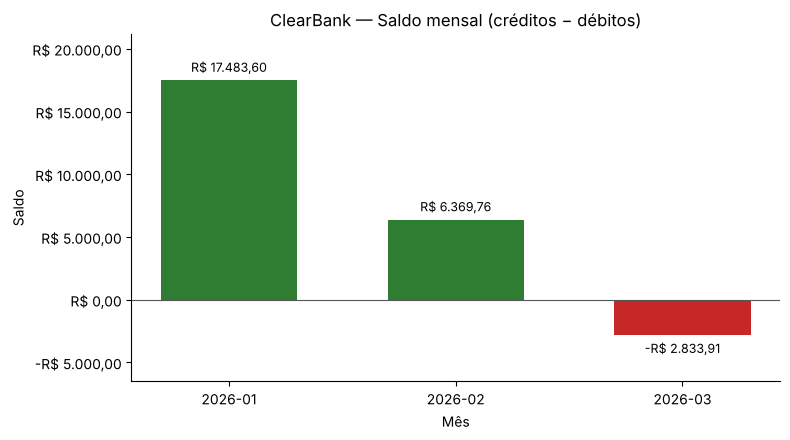

Gráfico salvo em: /home/claude/clearbank-analise/grafico.png


PosixPath('/home/claude/clearbank-analise/grafico.png')

In [17]:
def gerar_grafico_saldo(relatorio, caminho):
    try:
        import matplotlib.pyplot as plt
        from matplotlib.ticker import FuncFormatter
    except ImportError:
        print("matplotlib não está instalado: gráfico opcional não gerado.")
        return None

    if relatorio is None:
        print("Análise principal não executada: gráfico não gerado.")
        return None
    meses = list(relatorio["resumo_mensal"])
    if not meses:
        print("Sem meses com transações válidas: gráfico não gerado.")
        return None

    saldos = [float(relatorio["resumo_mensal"][mes]["saldo"]) for mes in meses]
    cores = ["#2e7d32" if saldo >= 0 else "#c62828" for saldo in saldos]

    figura, eixo = plt.subplots(figsize=(8, 4.5))
    barras = eixo.bar(meses, saldos, color=cores, width=0.6)
    eixo.axhline(0, color="#555555", linewidth=0.8)
    eixo.bar_label(barras, labels=[formatar_moeda(s) for s in saldos], padding=4, fontsize=9)
    eixo.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: formatar_moeda(valor)))
    eixo.margins(y=0.18)
    eixo.set_title("ClearBank — Saldo mensal (créditos − débitos)")
    eixo.set_xlabel("Mês")
    eixo.set_ylabel("Saldo")
    eixo.spines[["top", "right"]].set_visible(False)
    figura.tight_layout()
    figura.savefig(caminho, dpi=150)
    plt.show()
    plt.close(figura)
    print(f"Gráfico salvo em: {caminho}")
    return Path(caminho)


gerar_grafico_saldo(relatorio, CAMINHO_GRAFICO)

## 14. Verificação dos arquivos gerados

Confere se os arquivos existem na pasta do projeto, se o JSON é válido e mostra o início do conteúdo gravado.

In [18]:
for caminho in (CAMINHO_CSV, CAMINHO_JSON, CAMINHO_GRAFICO):
    status = f"{caminho.stat().st_size:>7} bytes" if caminho.exists() else "   (não encontrado)"
    print(f"{caminho.name:<16} {status}")

assert CAMINHO_JSON.exists(), "relatorio.json não foi gerado"
with open(CAMINHO_JSON, encoding="utf-8") as arquivo:
    conteudo = json.load(arquivo)
print("\nrelatorio.json é um JSON válido. Chaves de topo:", ", ".join(conteudo))
print("\nTrecho do arquivo:")
print("\n".join(CAMINHO_JSON.read_text(encoding="utf-8").splitlines()[:30]))
print("...")

transacoes.csv      1603 bytes
relatorio.json      3588 bytes
grafico.png        57768 bytes

relatorio.json é um JSON válido. Chaves de topo: gerado_em, total_transacoes_lidas, total_transacoes_validas, total_transacoes_invalidas, limite_suspeito, periodo_analisado, resumo_mensal, transacoes_suspeitas, registros_rejeitados, ids_duplicados

Trecho do arquivo:
{
  "gerado_em": "2026-10-17",
  "total_transacoes_lidas": 27,
  "total_transacoes_validas": 17,
  "total_transacoes_invalidas": 10,
  "limite_suspeito": 10000.00,
  "periodo_analisado": {
    "inicio": "2026-01-05",
    "fim": "2026-03-30",
    "intervalo_dias": 84
  },
  "resumo_mensal": {
    "2026-01": {
      "quantidade": 5,
      "total_credito": 18500.00,
      "total_debito": 1016.40,
      "saldo": 17483.60,
      "media_por_transacao": 3903.28,
      "maior_transacao": {
        "id": 3,
        "cliente_id": "C003",
        "data": "2026-01-12",
        "tipo": "credito",
        "valor": 15000.00
      },
      "menor

## 15. Conclusões e possíveis melhorias

**O que a análise mostra (dados de demonstração):**

- Das 27 linhas lidas, 10 foram rejeitadas — cada uma com o motivo registrado — e nenhuma interrompeu o processamento.
- Janeiro e fevereiro fecharam com saldo positivo; março ficou negativo, puxado por um débito de R$ 10.000,01.
- Três transações passaram do limite de R$ 10.000,00. A de exatamente R$ 10.000,00 (id 7) não foi sinalizada, como exige a regra de "estritamente maior".
- O id 16 aparece duas vezes com os mesmos dados. Como o enunciado não define regra de deduplicação, as duas linhas foram mantidas e o caso foi apenas reportado.

**Possíveis melhorias:**

- Definir com a área de negócio uma regra de deduplicação (por exemplo, `id` + `data` + `valor`).
- Aceitar valores no formato brasileiro (`1.500,00`) e detectar automaticamente a codificação do arquivo.
- Limites de suspeição por cliente ou por histórico, em vez de um valor fixo.
- Separar as funções em um módulo `.py` e os testes em `pytest`, mantendo o notebook como apresentação.
- Registrar as rejeições em um arquivo próprio (`rejeitados.csv`) para correção na origem.